# MoveInSync — Review Collection and Analysis

## Objective
This notebook supports the case-study question: **What is the current Play Store rating context, what do reviews say about the employee experience, and which issues should MoveInSync investigate first?**

It has two separate analysis tracks:
1. **Overall context:** listing-level rating/ratings count (when accessible), plus a review sample covering all star ratings.
2. **Diagnosis:** a separate sample of 1- and 2-star reviews, used to discover reported pain points.

The notebook also fetches a small set of public MoveInSync Help Center pages, creates charts and exports source logs and analysis files.

### Important sampling notes
- Targets are ceilings, not guarantees.
- Review collection through a third-party package can be blocked or change.
- The accessible review sample is not a probability sample of all historical reviews or all employees.
- Monthly review counts are not normalized by total trips, active users or total reviews.
- Theme tags are suggestions; manually audit them before using them as findings.
- Never report counts or conclusions that you have not verified against the generated CSVs.

## 1. Install dependencies

In [ ]:
%pip -q install google-play-scraper pandas matplotlib seaborn requests beautifulsoup4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.0 MB/s eta 0:00:00


## 2. Imports and configuration

In [ ]:
from google_play_scraper import app, reviews, Sort
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests, re, json, time, hashlib, shutil
from bs4 import BeautifulSoup
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display

APP_ID = "com.moveinsync.ets"
COUNTRY = "in"
LANGUAGE = "en"

# Tune these ceilings to the time and source coverage available.
ALL_RATING_TARGET = 1000
LOW_STAR_TARGET_PER_SCORE = 150   # target 150 each for 1-star and 2-star
PAGE_SIZE = 200
MAX_PAGES_ALL = 5                 # up to ~1,000 newest accessible reviews
MAX_PAGES_LOW_SCORE = 3            # additional candidates per star
RANDOM_SEED = 42

OUT = Path("moveinsync_review_analysis")
OUT.mkdir(exist_ok=True)

PLAY_STORE_URL = f"https://play.google.com/store/apps/details?id={APP_ID}&hl=en_IN&gl=IN"
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
print("Output folder:", OUT.resolve())
print("Run started UTC:", RUN_STARTED_UTC)

Output folder: /content/moveinsync_review_analysis
Run started UTC: 2026-10-11T14:51:32.512115+00:00


## 3. Capture listing-level context

In [ ]:
listing = {
    "app_id": APP_ID,
    "country": COUNTRY,
    "language": LANGUAGE,
    "source_url": PLAY_STORE_URL,
    "collected_at_utc": datetime.now(timezone.utc).isoformat(),
}
try:
    info = app(APP_ID, lang=LANGUAGE, country=COUNTRY)
    for key in ["title", "score", "ratings", "reviews", "installs", "minInstalls",
                "updated", "version", "released", "genre", "url", "histogram"]:
        if key in info:
            value = info[key]
            if hasattr(value, "isoformat"):
                value = value.isoformat()
            listing[key] = value
    listing["status"] = "success"
except Exception as e:
    listing["status"] = "failed"
    listing["error"] = repr(e)
    print("Listing request failed:", repr(e))

with open(OUT / "listing_snapshot.json", "w", encoding="utf-8") as f:
    json.dump(listing, f, indent=2, ensure_ascii=False, default=str)

display(pd.DataFrame([{
    "app": listing.get("title", "MoveInSync"),
    "displayed_score": listing.get("score"),
    "total_ratings": listing.get("ratings"),
    "review_count_field": listing.get("reviews"),
    "last_updated": listing.get("updated"),
    "version": listing.get("version"),
    "status": listing.get("status")
}]))
print("Rating histogram if exposed:", listing.get("histogram"))

## 4. Collection helper

The collector uses the newest accessible review pages and stops at the configured ceiling or when the source returns no more pages. It records collection errors so a shortfall is visible.

In [ ]:
def fetch_pages(score=None, max_pages=5, target=None, label="reviews"):
    records, token = [], None
    log = {
        "label": label, "score_filter": score, "target": target,
        "max_pages": max_pages, "pages_attempted": 0, "pages_succeeded": 0,
        "errors": []
    }
    for page_idx in range(max_pages):
        if target is not None and len(records) >= target:
            break
        try:
            kwargs = {
                "app_id": APP_ID, "lang": LANGUAGE, "country": COUNTRY,
                "sort": Sort.NEWEST, "count": PAGE_SIZE
            }
            if score is not None:
                kwargs["filter_score"] = score
            if token is not None:
                kwargs["continuation_token"] = token
            batch, next_token = reviews(**kwargs)
            log["pages_attempted"] += 1
            log["pages_succeeded"] += 1
            if not batch:
                break
            records.extend(batch)
            token = next_token
            print(f"{label}: page {page_idx+1}, fetched {len(batch)}, total {len(records)}")
            if not token:
                break
            time.sleep(0.8)
        except Exception as e:
            log["pages_attempted"] += 1
            log["errors"].append(repr(e))
            print(f"{label}: collection stopped:", repr(e))
            break
    log["records_returned_before_dedup"] = len(records)
    return records, log

all_records, all_log = fetch_pages(
    score=None, max_pages=MAX_PAGES_ALL,
    target=ALL_RATING_TARGET, label="All-rating recent sample"
)

low_records, low_logs = [], []
for star in [1, 2]:
    batch, log = fetch_pages(
        score=star, max_pages=MAX_PAGES_LOW_SCORE,
        target=LOW_STAR_TARGET_PER_SCORE, label=f"{star}-star diagnostic"
    )
    low_records.extend(batch)
    low_logs.append(log)

print("All-rating records:", len(all_records))
print("Additional low-star records:", len(low_records))

All-rating recent sample: page 1, fetched 200, total 200
All-rating recent sample: page 2, fetched 200, total 400
All-rating recent sample: page 3, fetched 200, total 600
All-rating recent sample: page 4, fetched 200, total 800
All-rating recent sample: page 5, fetched 200, total 1000
1-star diagnostic: collection stopped: TypeError("reviews() got an unexpected keyword argument 'filter_score'. Did you mean 'filter_score_with'?")
2-star diagnostic: collection stopped: TypeError("reviews() got an unexpected keyword argument 'filter_score'. Did you mean 'filter_score_with'?")
All-rating records: 1000
Additional low-star records: 0


## 5. Normalize and deduplicate reviews

In [ ]:
def normalize_record(r, collection_source):
    text = (r.get("content") or "").strip()
    created = r.get("at")
    if hasattr(created, "isoformat"):
        created = created.isoformat()
    fingerprint = r.get("reviewId") or hashlib.sha256(
        f"{r.get('score')}|{created}|{text}".encode("utf-8", errors="ignore")
    ).hexdigest()
    return {
        "review_id": str(fingerprint),
        "review_date": created,
        "star_rating": r.get("score"),
        "review_text": text,
        "review_char_count": len(text),
        "thumbs_up_count": r.get("thumbsUpCount"),
        "app_version": r.get("reviewCreatedVersion"),
        "developer_reply_present": bool(r.get("replyContent")),
        "developer_reply_date": str(r.get("repliedAt")) if r.get("repliedAt") else None,
        "source_url": PLAY_STORE_URL,
        "collection_source": collection_source,
        "collected_at_utc": datetime.now(timezone.utc).isoformat()
    }

records = [normalize_record(r, "recent_all_ratings") for r in all_records]
records += [normalize_record(r, "low_star_diagnostic") for r in low_records]
df = pd.DataFrame(records)

if df.empty:
    print("No reviews collected. Check connectivity/source availability and rerun later.")
else:
    df["review_date"] = pd.to_datetime(df["review_date"], errors="coerce", utc=True)
    df["star_rating"] = pd.to_numeric(df["star_rating"], errors="coerce").astype("Int64")

    source_map = df.groupby("review_id")["collection_source"].apply(
        lambda s: ";".join(sorted(set(s.dropna().astype(str))))
    )
    df = df.sort_values("review_date").drop_duplicates("review_id", keep="last").copy()
    df["collection_source"] = df["review_id"].map(source_map)
    df = df.sort_values("review_date", ascending=False).reset_index(drop=True)

    print("Unique review count:", len(df))
    print("Date range:", df["review_date"].min(), "to", df["review_date"].max())
    display(df["star_rating"].value_counts(dropna=False).sort_index().rename_axis("stars").to_frame("sample_count"))

Unique review count: 1000
Date range: 2026-06-14 13:18:43+00:00 to 2026-10-09 12:41:59+00:00


,sample_count
stars,
1,259
2,33
3,26
4,42
5,640


## 6. Classify complaint themes

This uses transparent keyword rules, not a trained classifier. A review can receive multiple tags. Tags are hypotheses and should be checked manually before they are presented as conclusions.

In [ ]:
THEME_RULES = {
    "booking_scheduling": r"book|booking|schedule|scheduled|shift|date|cancel|cancellation|ride",
    "gps_eta_tracking": r"gps|live location|location|tracking|track|eta|arrival|pickup time|drop time|map",
    "driver_vehicle_operations": r"driver|vehicle|cab|shuttle|route|pickup|drop|late cab|missed pickup",
    "notifications_alerts": r"notification|alert|reminder|push|otp|sms|email not received|not receive",
    "crash_performance_network": r"crash|crashing|slow|loading|hang|freeze|stuck|network|server|error|bug",
    "ux_usability": r"ui|interface|confus|difficult to use|design|step|button|screen|user friendly",
    "login_access": r"login|log in|sign in|password|access denied|not able to login",
    "no_show_checkin": r"no.show|no show|check.in|check in|boarding|deduct|salary",
    "customer_support": r"support|helpdesk|complaint|response|respond|customer care|transport manager",
}
def classify_themes(text):
    text = (text or "").lower()
    tags = [name for name, pattern in THEME_RULES.items() if re.search(pattern, text)]
    return ";".join(tags) if tags else "other_unclear"

if not df.empty:
    df["theme_tags_rule_based"] = df["review_text"].fillna("").map(classify_themes)
    df["is_low_rating"] = df["star_rating"].isin([1, 2])
    df["review_month"] = df["review_date"].dt.to_period("M").astype(str)
    df.to_csv(OUT / "MoveInSync_Public_Reviews_Combined.csv", index=False)
    print("Saved review CSV.")

Saved review CSV.


/tmp/ipykernel_2388/3339907069.py:20: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["review_month"] = df["review_date"].dt.to_period("M").astype(str)


## 7. Analyze rating distribution and low-star share

In [ ]:
if not df.empty:
    rating_counts = df["star_rating"].value_counts().reindex([1,2,3,4,5], fill_value=0)
    rating_summary = pd.DataFrame({
        "stars": rating_counts.index,
        "review_count": rating_counts.values,
        "sample_share_percent": (rating_counts / max(rating_counts.sum(), 1) * 100).round(2)
    })
    display(rating_summary)

    low_count = int(df["star_rating"].isin([1,2]).sum())
    total_count = int(len(df))
    print(f"Low-star reviews in collected sample: {low_count}/{total_count} ({low_count/total_count*100:.1f}%)" if total_count else "No data")

    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(7,4))
    sns.barplot(x=rating_summary["stars"].astype(str), y=rating_summary["review_count"])
    plt.title("Star Ratings in Collected Review Sample")
    plt.xlabel("Star rating")
    plt.ylabel("Number of reviews")
    plt.tight_layout()
    plt.savefig(OUT / "rating_distribution_sample.png", dpi=180, bbox_inches="tight")
    plt.show()

## 8. Analyze complaint themes

,review_mentions
other_unclear,111
driver_vehicle_operations,73
booking_scheduling,64
crash_performance_network,49
gps_eta_tracking,39
ux_usability,34
notifications_alerts,29
customer_support,15
login_access,14
no_show_checkin,10


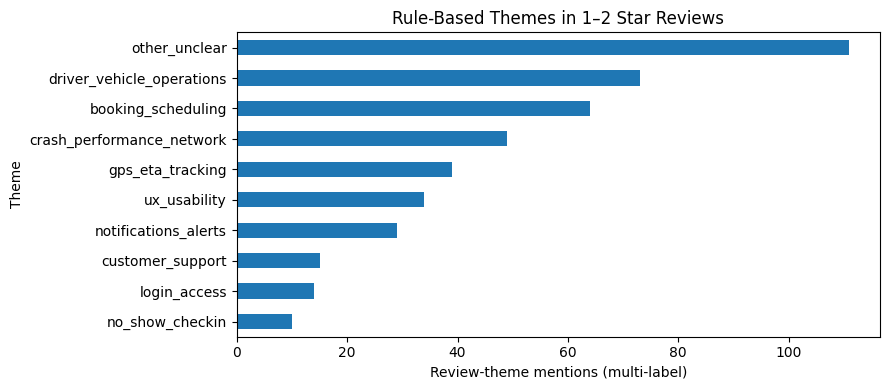

Positive review sample: 682


,star_rating,review_date,review_char_count,theme_tags_rule_based
1,5,2026-10-09 11:25:33+00:00,4,other_unclear
4,5,2026-10-09 03:44:34+00:00,4,other_unclear
6,5,2026-10-09 02:19:38+00:00,34,other_unclear
7,5,2026-10-08 23:37:34+00:00,14,other_unclear
8,5,2026-10-08 19:43:12+00:00,23,other_unclear
9,5,2026-10-08 18:04:50+00:00,9,other_unclear
11,5,2026-10-08 11:21:16+00:00,6,other_unclear
13,5,2026-10-08 09:49:34+00:00,24,ux_usability
16,5,2026-10-08 00:45:54+00:00,6,other_unclear
17,5,2026-10-08 00:28:36+00:00,46,booking_scheduling


In [ ]:
if not df.empty:
    low_df = df[df["star_rating"].isin([1,2])].copy()
    theme_counts = {}
    for tags in low_df["theme_tags_rule_based"].fillna("other_unclear"):
        for tag in str(tags).split(";"):
            theme_counts[tag] = theme_counts.get(tag, 0) + 1

    themes = pd.Series(theme_counts, name="review_mentions").sort_values(ascending=False)
    display(themes.to_frame())
    if not themes.empty:
        plot_themes = themes.sort_values()
        plt.figure(figsize=(9, max(4, len(plot_themes)*0.4)))
        plot_themes.plot(kind="barh")
        plt.title("Rule-Based Themes in 1–2 Star Reviews")
        plt.xlabel("Review-theme mentions (multi-label)")
        plt.ylabel("Theme")
        plt.tight_layout()
        plt.savefig(OUT / "low_star_theme_counts.png", dpi=180, bbox_inches="tight")
        plt.show()

    # Positive reviews help identify strengths worth preserving.
    positive_df = df[df["star_rating"].isin([4,5])]
    print("Positive review sample:", len(positive_df))
    display(positive_df[["star_rating", "review_date", "review_char_count", "theme_tags_rule_based"]].head(10))

## 9. Analyze review timing

/tmp/ipykernel_2388/1758452126.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_counts = dated.groupby(dated["review_date"].dt.to_period("M")).size()


,review_count
review_date,
2026-06,150
2026-07,286
2026-08,241
2026-09,245
2026-10,78


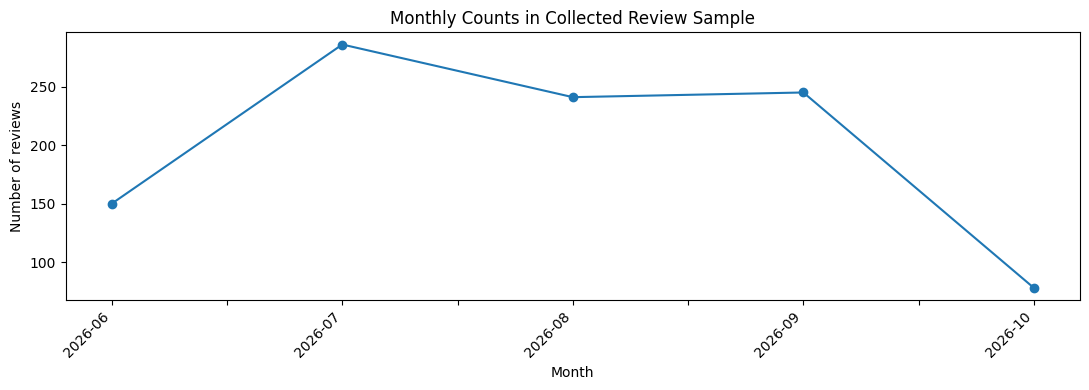

theme
month
2026-06
2026-07
2026-08
2026-09
2026-10


In [ ]:
if not df.empty:
    dated = df.dropna(subset=["review_date"]).copy()
    monthly_counts = dated.groupby(dated["review_date"].dt.to_period("M")).size()
    monthly_counts.index = monthly_counts.index.astype(str)
    display(monthly_counts.rename("review_count").to_frame())

    if not monthly_counts.empty:
        plt.figure(figsize=(11,4))
        monthly_counts.plot(marker="o")
        plt.title("Monthly Counts in Collected Review Sample")
        plt.xlabel("Month")
        plt.ylabel("Number of reviews")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.savefig(OUT / "monthly_review_counts_sample.png", dpi=180, bbox_inches="tight")
        plt.show()

    # Theme-by-month table helps spot changes; not normalized for trip volume.
    low_dated = dated[dated["star_rating"].isin([1,2])]
    month_theme_rows = []
    for _, row in low_dated.iterrows():
        for tag in str(row.get("theme_tags_rule_based", "other_unclear")).split(";"):
            month_theme_rows.append({"month": row["review_date"].strftime("%Y-%m"), "theme": tag})
    if month_theme_rows:
        month_theme = pd.DataFrame(month_theme_rows).pivot_table(
            index="month", columns="theme", values="theme", aggfunc="count", fill_value=0
        )
        display(month_theme)
        month_theme.to_csv(OUT / "low_star_theme_by_month.csv")

## 10. Fetch selected public internet sources

This retrieves a limited set of public pages and logs the HTTP status, title and text excerpt if accessible. It does not crawl the entire internet. Help Center content documents support topics but does not establish how common a problem is.

In [ ]:
SOURCES = [
    {
        "type": "Google Play listing",
        "url": PLAY_STORE_URL,
        "purpose": "Listing context and public app information"
    },
    {
        "type": "MoveInSync Help Center - Mobile App Issues",
        "url": "https://helpcenter.moveinsync.com/support/solutions/articles/1070000136108-mobile-app-issues",
        "purpose": "Documented app troubleshooting topics"
    },
    {
        "type": "MoveInSync Help Center - Knowledge Base",
        "url": "https://helpcenter.moveinsync.com/support/solutions",
        "purpose": "Publicly documented support topics"
    },
    {
        "type": "MoveInSync Help Center - Home",
        "url": "https://helpcenter.moveinsync.com/support/home",
        "purpose": "Index of public support resources"
    },
]

def fetch_source(source):
    out = {
        **source, "fetched_at_utc": datetime.now(timezone.utc).isoformat(),
        "http_status": None, "title": None, "fetch_status": "failed",
        "text_excerpt": "", "error": None
    }
    try:
        resp = requests.get(source["url"], timeout=20,
                            headers={"User-Agent": "Mozilla/5.0 (compatible; PublicResearchNotebook/1.0)"})
        out["http_status"] = resp.status_code
        resp.raise_for_status()
        soup = BeautifulSoup(resp.text, "html.parser")
        for tag in soup(["script", "style", "noscript", "svg"]):
            tag.decompose()
        out["title"] = soup.title.get_text(" ", strip=True) if soup.title else ""
        out["text_excerpt"] = re.sub(r"\s+", " ", soup.get_text(" ", strip=True)).strip()[:2500]
        out["fetch_status"] = "success"
    except Exception as e:
        out["error"] = repr(e)
    return out

source_rows = []
for source in SOURCES:
    print("Fetching:", source["url"])
    source_rows.append(fetch_source(source))
    time.sleep(1)

source_df = pd.DataFrame(source_rows)
source_df.to_csv(OUT / "Public_Web_Source_Log.csv", index=False)
display(source_df[["type", "http_status", "fetch_status", "title", "url"]])

Fetching: https://play.google.com/store/apps/details?id=com.moveinsync.ets&hl=en_IN&gl=IN
Fetching: https://helpcenter.moveinsync.com/support/solutions/articles/1070000136108-mobile-app-issues
Fetching: https://helpcenter.moveinsync.com/support/solutions
Fetching: https://helpcenter.moveinsync.com/support/home


,type,http_status,fetch_status,title,url
0,Google Play listing,200,success,MoveInSync – Apps on Google Play,https://play.google.com/store/apps/details?id=...
1,MoveInSync Help Center - Mobile App Issues,200,success,Mobile App Issues : MoveInSync Help Center,https://helpcenter.moveinsync.com/support/solu...
2,MoveInSync Help Center - Knowledge Base,200,success,Knowledge base : MoveInSync Help Center,https://helpcenter.moveinsync.com/support/solu...
3,MoveInSync Help Center - Home,200,success,Home | Support : MoveInSync Help Center,https://helpcenter.moveinsync.com/support/home


## 11. Create a manual review audit sample

In [ ]:
if not df.empty:
    audit_df = df.sample(n=min(50, len(df)), random_state=RANDOM_SEED).copy()
    audit_df["human_verified_theme"] = ""
    audit_df["human_notes"] = ""
    audit_df[[
        "review_date", "star_rating", "review_text", "theme_tags_rule_based",
        "human_verified_theme", "human_notes", "source_url"
    ]].to_csv(OUT / "Manual_Review_Audit_Template.csv", index=False)
    print("Saved Manual_Review_Audit_Template.csv. Fill the human_verified_theme and human_notes columns after reading each review.")

Saved Manual_Review_Audit_Template.csv. Fill the human_verified_theme and human_notes columns after reading each review.


## 12. Save collection metadata and findings summary

Use actual run values in the report. Listing-level rating and sample-level rating proportions are different measures; label them separately.

In [ ]:
import json

# Safely load listing from the saved file if it's missing from the current namespace
if 'listing' not in globals():
    try:
        with open(OUT / "listing_snapshot.json", "r", encoding="utf-8") as f:
            listing = json.load(f)
    except Exception:
        listing = {}

metadata = {
    "run_started_utc": RUN_STARTED_UTC,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(),
    "app_id": APP_ID, "country": COUNTRY, "language": LANGUAGE,
    "listing_status": listing.get("status"),
    "all_rating_collection_log": all_log,
    "low_star_collection_logs": low_logs,
    "unique_review_count": int(len(df)) if not df.empty else 0,
    "sample_rating_counts": ({str(k): int(v) for k,v in df["star_rating"].value_counts(dropna=False).items()} if not df.empty else {}),
    "limitations": [
        "Recent accessible reviews form a convenience sample, not a representative historical sample.",
        "Rule-based theme tags require manual validation.",
        "Monthly review counts are not normalized by trips or active users.",
        "Public pages cannot verify internal root causes."
    ]
}
with open(OUT / "collection_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False, default=str)

findings = {
    "listing_context": {
        "displayed_score": listing.get("score"),
        "total_ratings": listing.get("ratings"),
        "updated": listing.get("updated"),
        "status": listing.get("status")
    },
    "unique_sample_count": int(len(df)) if not df.empty else 0,
    "low_star_sample_count": int(df["star_rating"].isin([1,2]).sum()) if not df.empty else 0,
    "sample_rating_counts": metadata["sample_rating_counts"],
    "interpretation": "Sample findings are diagnostic signals, not estimates of all user or trip experiences."
}
with open(OUT / "Findings_Summary.json", "w", encoding="utf-8") as f:
    json.dump(findings, f, indent=2, ensure_ascii=False, default=str)

print(json.dumps(findings, indent=2, default=str))

{
  "listing_context": {
    "displayed_score": null,
    "total_ratings": null,
    "updated": null,
    "status": null
  },
  "unique_sample_count": 1000,
  "low_star_sample_count": 292,
  "sample_rating_counts": {
    "5": 640,
    "1": 259,
    "4": 42,
    "2": 33,
    "3": 26
  },
  "interpretation": "Sample findings are diagnostic signals, not estimates of all user or trip experiences."
}


## 13. Download the outputs

In [ ]:
zip_path = shutil.make_archive("MoveInSync_Review_Analysis_Outputs", "zip", OUT)
print("Created:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Outside Google Colab: download the ZIP from the notebook file browser.")

Created: /content/MoveInSync_Review_Analysis_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_2388/1085018742.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_len, x="star_rating", y="review_char_count", palette="Blues_d")


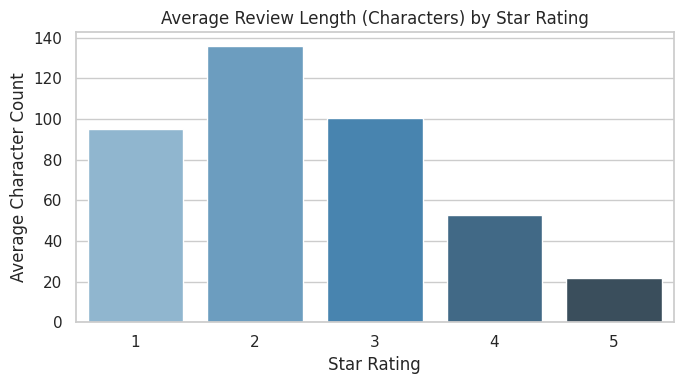

/tmp/ipykernel_2388/1085018742.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=themes_series.values, y=themes_series.index, palette="Reds_r")


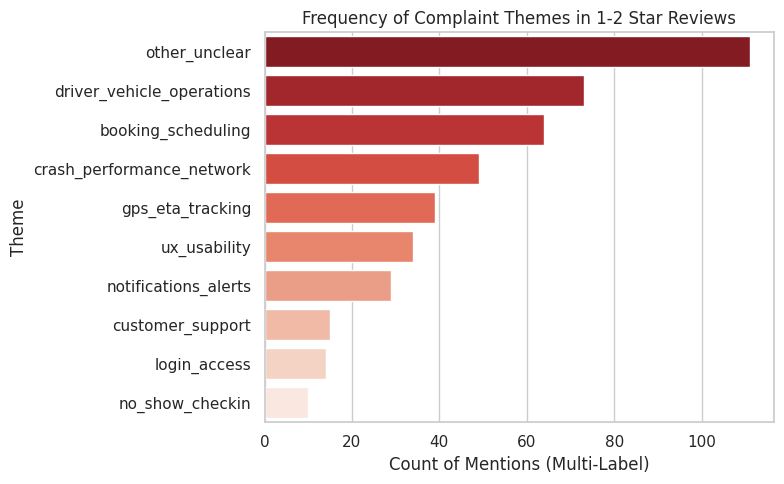

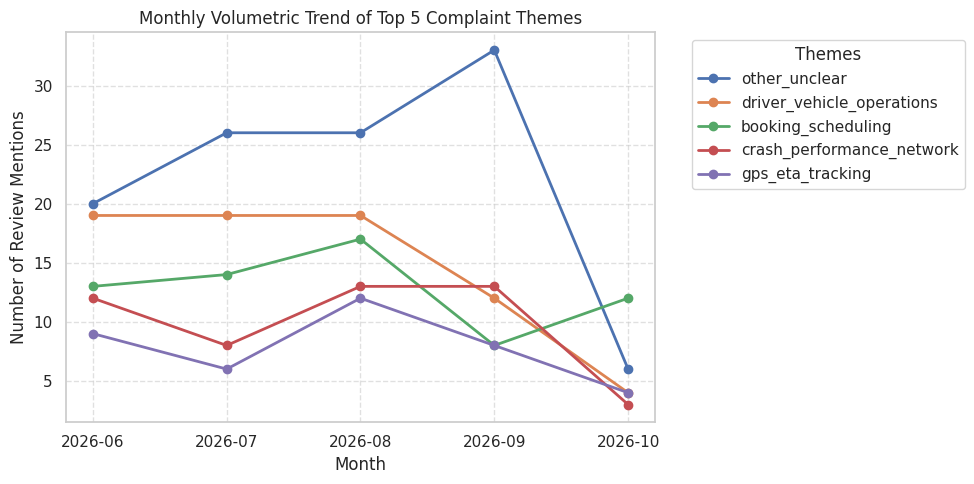

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUT = Path("moveinsync_review_analysis")
sns.set_theme(style="whitegrid")

# Ensure df is available and not empty
if 'df' in globals() and not df.empty:
    # 1. Average Review Character Count by Star Rating
    plt.figure(figsize=(7, 4))
    avg_len = df.groupby("star_rating")["review_char_count"].mean().reset_index()
    sns.barplot(data=avg_len, x="star_rating", y="review_char_count", palette="Blues_d")
    plt.title("Average Review Length (Characters) by Star Rating")
    plt.xlabel("Star Rating")
    plt.ylabel("Average Character Count")
    plt.tight_layout()
    plt.savefig(OUT / "average_review_length_by_star.png", dpi=180, bbox_inches="tight")
    plt.show()

    # 2. Main Complaint Themes Proportion among Low-Star Reviews (1-2 stars)
    low_star_mask = df["star_rating"].isin([1, 2])
    low_star_reviews = df[low_star_mask].copy()

    # Flatten themes if multi-labeled
    themes_list = []
    for t_str in low_star_reviews["theme_tags_rule_based"].dropna():
        themes_list.extend(t_str.split(";"))

    if themes_list:
        themes_series = pd.Series(themes_list).value_counts()
        plt.figure(figsize=(8, 5))
        sns.barplot(x=themes_series.values, y=themes_series.index, palette="Reds_r")
        plt.title("Frequency of Complaint Themes in 1-2 Star Reviews")
        plt.xlabel("Count of Mentions (Multi-Label)")
        plt.ylabel("Theme")
        plt.tight_layout()
        plt.savefig(OUT / "complaint_themes_distribution.png", dpi=180, bbox_inches="tight")
        plt.show()

    # 3. Monthly Trend of Top Complaint Themes
    # Reshape month_theme data
    month_theme_rows = []
    for _, row in low_star_reviews.iterrows():
        month = row["review_date"].strftime("%Y-%m")
        for tag in str(row.get("theme_tags_rule_based", "other_unclear")).split(";"):
            month_theme_rows.append({"month": month, "theme": tag})

    if month_theme_rows:
        trend_df = pd.DataFrame(month_theme_rows)
        trend_pivot = trend_df.groupby(["month", "theme"]).size().unstack(fill_value=0)

        # Select top 5 themes for visual clarity
        top_themes = trend_df["theme"].value_counts().head(5).index
        trend_pivot_filtered = trend_pivot[top_themes]

        plt.figure(figsize=(10, 5))
        for col in trend_pivot_filtered.columns:
            plt.plot(trend_pivot_filtered.index, trend_pivot_filtered[col], marker='o', label=col, linewidth=2)

        plt.title("Monthly Volumetric Trend of Top 5 Complaint Themes")
        plt.xlabel("Month")
        plt.ylabel("Number of Review Mentions")
        plt.legend(title="Themes", bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.tight_layout()
        plt.savefig(OUT / "low_star_themes_trend_monthly.png", dpi=180, bbox_inches="tight")
        plt.show()
else:
    print("Review DataFrame is empty or not loaded.")

In [ ]:
import shutil
# Re-pack the ZIP file to include the new visualizations
zip_path = shutil.make_archive("MoveInSync_Review_Analysis_Outputs", "zip", OUT)
print("Re-packaged output directory into:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Outside Colab environment: manual zip download required.")

Re-packaged output directory into: /content/MoveInSync_Review_Analysis_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>